In [34]:
import pandas as pd
import numpy as np

In [17]:
glac_data = pd.read_parquet("/Volumes/University_stuff/Code_Projects/Glaciation_time_estimator/Leibzig_data/Results/Leibzig_data/20150701.0000_20150730.0000_glac.parquet")
cloud_data = pd.read_parquet("/Volumes/University_stuff/Code_Projects/Glaciation_time_estimator/Leibzig_data/Results/Leibzig_data/20150701.0000_20150730.0000.parquet")

In [19]:
len(cloud_data)*12

275952

In [6]:
glac_data["avg_ctt"]-273.15

0     -16.796155
1     -27.119306
2     -18.822695
3     -12.013336
4      -8.503172
         ...    
522   -17.737321
523   -14.525758
524   -24.734270
525   -17.228341
526   -12.347043
Name: avg_ctt, Length: 527, dtype: float64

In [8]:
glac_data.keys()

Index(['Cloud_ID', 'Time [m]', 'Magnitude', 'Glac_start_ind', 'Glac_peak_ind',
       'Linear', 'line_rmse', 'Rate_arr', 'Mean_glac_rate',
       'Glaciation time [h]', 'tracknumber', 'is_large_pix_cloud',
       'is_cot_valid_cloud', 'is_ctp_valid_cloud', 'is_liq', 'is_mix',
       'is_ice', 'max_water_frac', 'max_ice_fraction', 'avg_size[km]',
       'max_size[km]', 'min_size[km]', 'avg_size[px]', 'max_size[px]',
       'min_size[px]', 'track_start_time', 'track_length', 'avg_cot',
       'avg_ctp', 'avg_ctt', 'glaciation_start_time', 'glaciation_end_time',
       'avg_lat', 'avg_lon', 'start_ice_fraction', 'end_ice_fraction',
       'ice_frac_hist', 'cot_hist', 'cot_std_hist', 'cot_nan_frac_hist',
       'ctp_hist', 'ctp_std_hist', 'ctp_nan_frac_hist', 'ctt_hist',
       'ctt_std_hist', 'lat_hist', 'lon_hist', 'size_hist_km',
       'size_hist_km_debug'],
      dtype='str')

In [21]:
glac_data["Peak IF"]= glac_data.apply(lambda row: row.ice_frac_hist[row["Glac_peak_ind"]],axis=1)
glac_data["survives_post_peak"] = glac_data.apply(lambda row: len(row.ice_frac_hist)>row["Glac_peak_ind"]+1,axis=1)

In [22]:
import matplotlib.pyplot as plt

In [16]:
glac_data["survives_post_peak"].value_counts()

survives_post_peak
True     278
False    249
Name: count, dtype: int64

In [28]:
glac_data["is_large_pix_cloud"].value_counts()

is_large_pix_cloud
False    527
Name: count, dtype: int64

In [42]:
cloud_data["temp_bin"]=pd.cut(glac_data["avg_ctt"]-273.15,bins=np.arange(-36,1,6))
glac_data["temp_bin"]=pd.cut(glac_data["avg_ctt"]-273.15,bins=np.arange(-36,1,6))

(array([  6.,  52., 162., 215.,  89.,   3.]),
 array([-36., -30., -24., -18., -12.,  -6.,   0.]),
 <BarContainer object of 6 artists>)

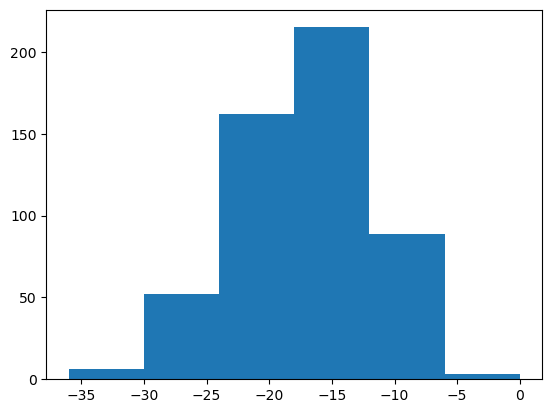

In [36]:
plt.hist(glac_data["avg_ctt"]-273.15,bins=np.arange(-36,1,6))

Text(0, 0.5, 'Counts')

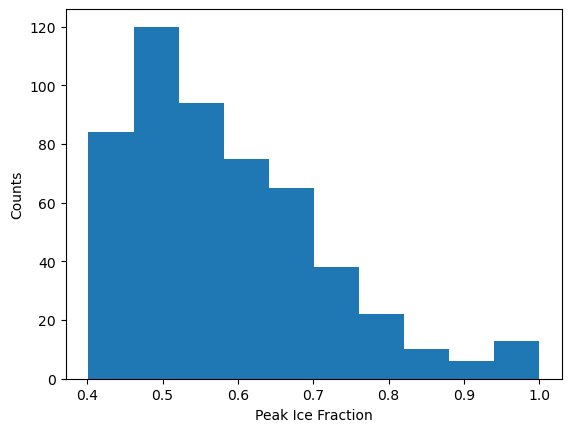

In [ ]:
plt.hist(glac_data["Peak IF"])
plt.xlabel("Peak Ice Fraction")
plt.ylabel("Counts")
plt.